In [ ]:
from google.colab import files
uploaded=files.upload()

Saving ai4i2020.csv to ai4i2020.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
df = pd.read_csv("ai4i2020.csv")
print("Dataset shape:", df.shape)

display(df.head())



Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
print(df.describe())

               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.000000   
mean    5000.50000           300.004930               310.005560   
std     2886.89568             2.000259                 1.483734   
min        1.00000           295.300000               305.700000   
25%     2500.75000           298.300000               308.800000   
50%     5000.50000           300.100000               310.100000   
75%     7500.25000           301.500000               311.100000   
max    10000.00000           304.500000               313.800000   

       Rotational speed [rpm]   Torque [Nm]  Tool wear [min]  Machine failure  \
count            10000.000000  10000.000000     10000.000000     10000.000000   
mean              1538.776100     39.986910       107.951000         0.033900   
std                179.284096      9.968934        63.654147         0.180981   
min               1168.000000      3.800000         0.000000   

In [ ]:
print(df.isnull().sum())


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [ ]:
print(df.duplicated().sum())


Duplicate Records:
0


In [ ]:
failure_counts = df["Machine failure"].value_counts()

print("Machine Failure Distribution:")
print(failure_counts)

print("\nPercentage Distribution:")
print(df["Machine failure"].value_counts())

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage Distribution:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


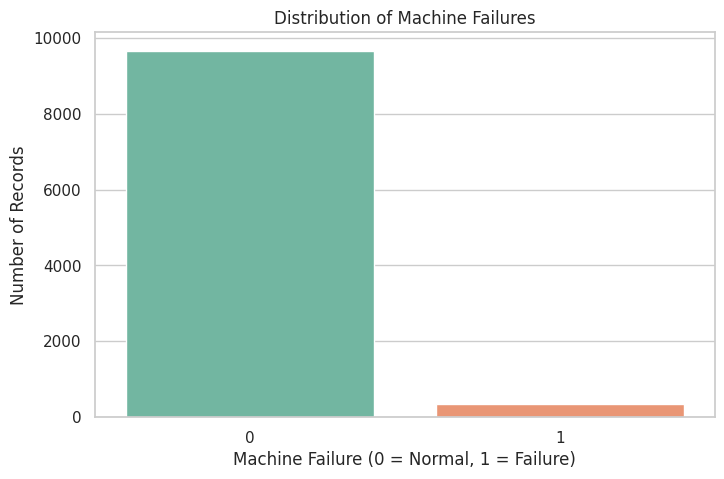

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Machine failure",
    hue="Machine failure",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Number of Records")

plt.show()

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


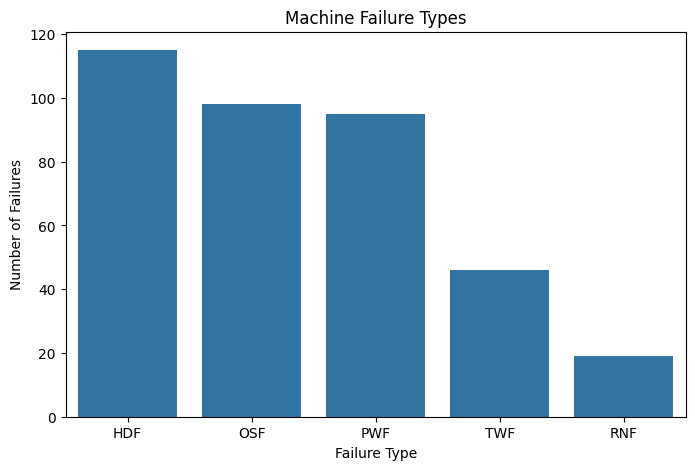

In [ ]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_counts = df[failure_modes].sum().sort_values(ascending=False)

print(failure_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=failure_counts.index, y=failure_counts.values)

plt.title("Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")

plt.show()

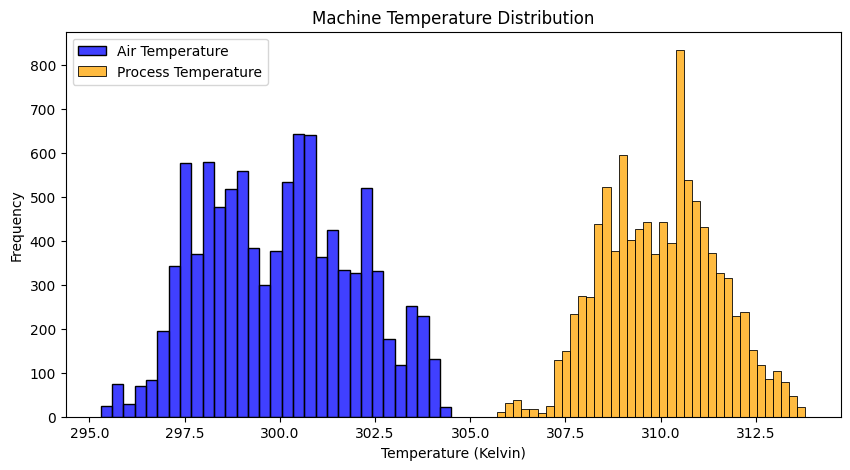

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Air temperature [K]"], color="blue", label="Air Temperature")
sns.histplot(df["Process temperature [K]"], color="orange", label="Process Temperature")

plt.title("Machine Temperature Distribution")
plt.xlabel("Temperature (Kelvin)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

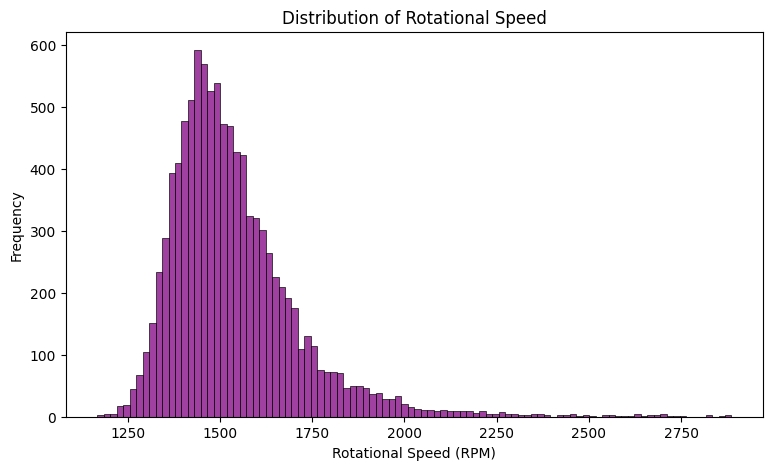

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(df["Rotational speed [rpm]"], color="purple")

plt.title("Distribution of Rotational Speed")
plt.xlabel("Rotational Speed (RPM)")
plt.ylabel("Frequency")

plt.show()

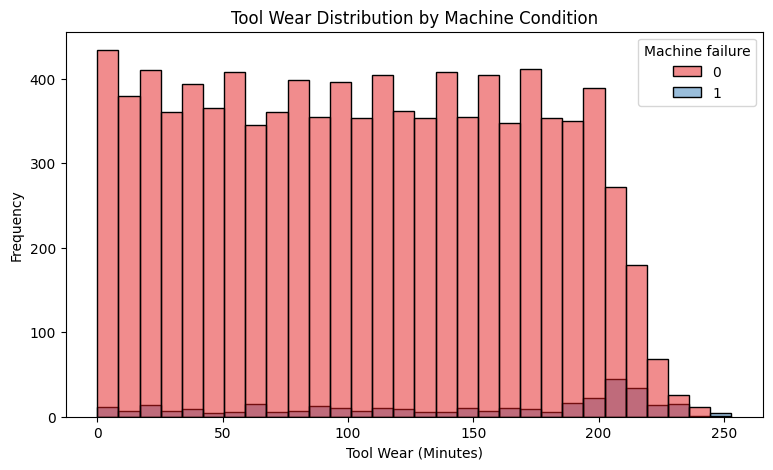

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df,
    x="Tool wear [min]",
    hue="Machine failure",
    bins=30,
    palette="Set1"
)

plt.title("Tool Wear Distribution by Machine Condition")
plt.xlabel("Tool Wear (Minutes)")
plt.ylabel("Frequency")

plt.show()

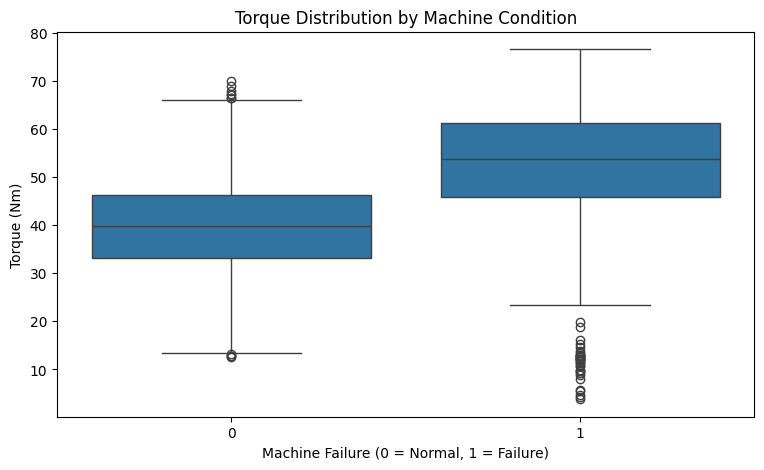

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df["Machine failure"],
    y=df["Torque [Nm]"]
)

plt.title("Torque Distribution by Machine Condition")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Torque (Nm)")

plt.show()

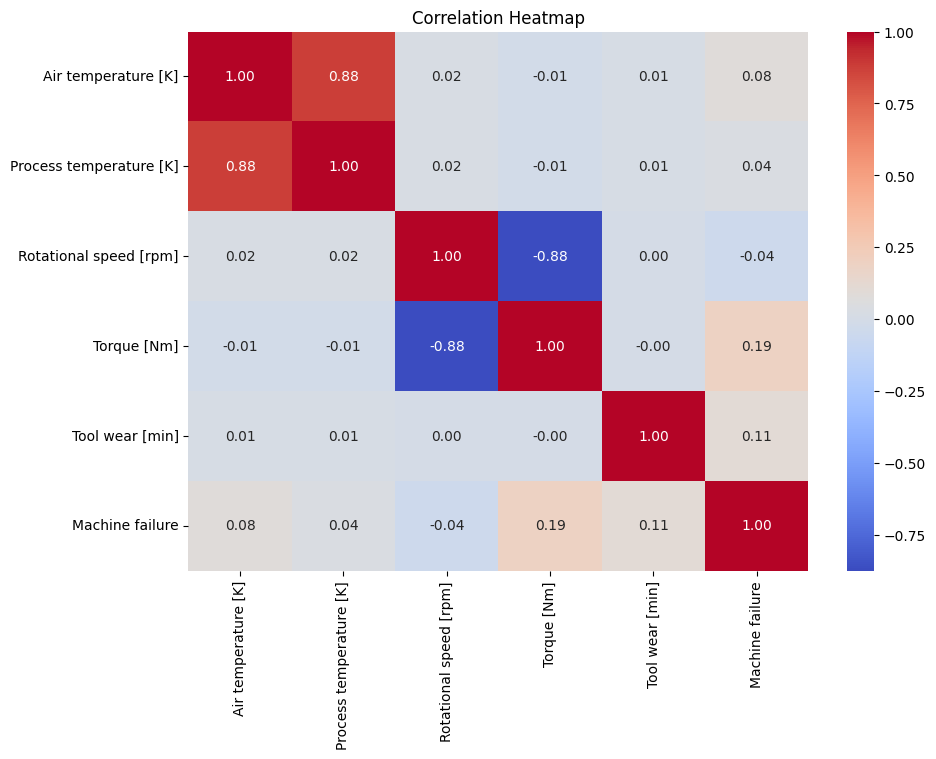

In [ ]:
corr_data = df[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]]

corr = corr_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64


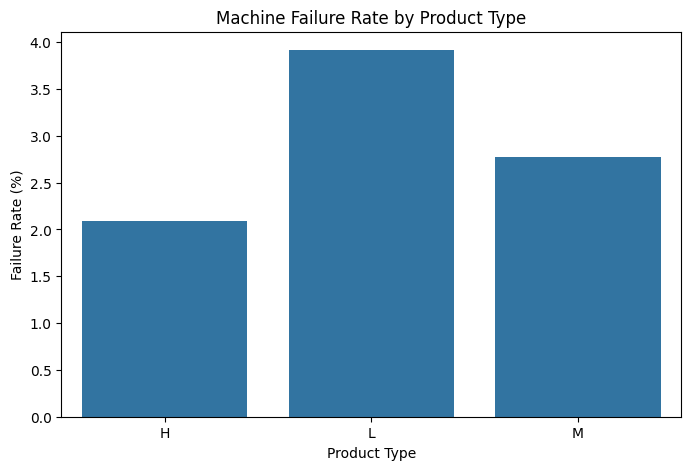

In [ ]:
type_failure = df.groupby("Type")["Machine failure"].mean() * 100

print(type_failure)

plt.figure(figsize=(8, 5))

sns.barplot(x=type_failure.index, y=type_failure.values)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

In [ ]:
X = df.drop(columns=["UDI", "Product ID", "Machine failure",
                     "TWF", "HDF", "PWF", "OSF", "RNF",
                     ])

y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

encoder = LabelEncoder()

X_train["Type"] = encoder.fit_transform(X_train["Type"])
X_test["Type"] = encoder.transform(X_test["Type"])

model = LogisticRegression(class_weight="balanced", max_iter=1000)

model.fit(X_train, y_train)




LogisticRegression(class_weight='balanced', max_iter=1000)

Accuracy: 82.05 %
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



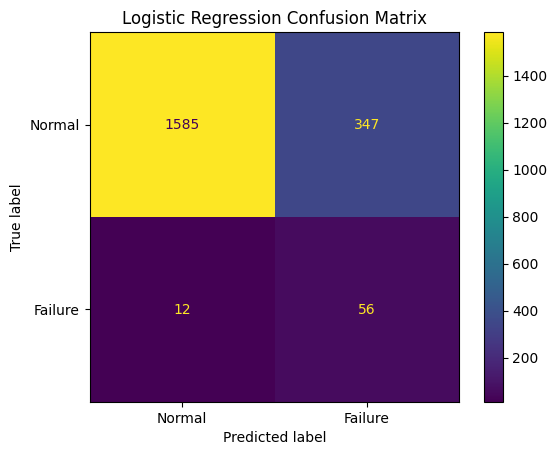

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred)*100,"%")

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm, display_labels=["Normal", "Failure"]).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()